In [1]:
# Install required packages
packages <- c(
  "data.table",
  "arrow",
  "ggplot2",
  "lubridate",
  "foreach",
  "doParallel",
  "microbenchmark",
  "purrr"
)

installed <- rownames(installed.packages())
missing <- packages[!packages %in% installed]

if (length(missing) > 0) {
  install.packages(
    missing,
    repos = "https://cloud.r-project.org"
  )
}

# Load libraries
library(data.table)
library(arrow)
library(ggplot2)
library(lubridate)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)

cat("R version:", R.version.string, "\n")
cat("All packages loaded successfully.\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp



Attaching package: ‘lubridate’


The following object is masked from ‘package:arrow’:

    duration


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose




R version: R version 4.6.1 (2026-06-24) 
All packages loaded successfully.


In [2]:
trip_url <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/trip-data/",
  "yellow_tripdata_2025-01.parquet"
)

zone_url <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/misc/",
  "taxi_zone_lookup.csv"
)

trip_file <- "yellow_tripdata_2025-01.parquet"
zone_file <- "taxi_zone_lookup.csv"

download.file(trip_url, trip_file, mode = "wb")
download.file(zone_url, zone_file, mode = "wb")

cat("Files downloaded successfully.\n")

Files downloaded successfully.


In [3]:
trips_raw <- as.data.table(
  arrow::read_parquet(trip_file)
)

zones <- fread(zone_file)

cat("Dataset dimensions:\n")
print(dim(trips_raw))

cat("\nColumn names:\n")
print(names(trips_raw))

cat("\nDataset structure:\n")
str(trips_raw)

cat("\nSummary statistics:\n")
print(summary(trips_raw))

cat("\nFirst six records:\n")
print(head(trips_raw))

Dataset dimensions:
[1] 3475226      20

Column names:
 [1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"           "cbd_congestion_fee"   

Dataset structure:
Classes ‘data.table’ and 'data.frame':	3475226 obs. of  20 variables:
 $ VendorID             : int  1 1 1 2 2 2 1 1 1 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2025-01-01 00:18:38" "2025-01-01 00:32:40" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2025-01-01 00:26:59" "2025-01-01 00:35:13" ...
 $ passenger_count      : int  1 1 1 3 3 2 0 0 0 1 ...
 $ trip_distance        : num  1.6 0.5 0.6 0.52 

In [4]:
required_cols <- c(
  "tpep_pickup_datetime",
  "tpep_dropoff_datetime",
  "PULocationID",
  "DOLocationID",
  "passenger_count",
  "trip_distance",
  "payment_type",
  "fare_amount",
  "tip_amount",
  "total_amount"
)

missing_cols <- setdiff(required_cols, names(trips_raw))

if (length(missing_cols) > 0) {
  stop(paste(
    "Missing columns:",
    paste(missing_cols, collapse = ", ")
  ))
}

trips <- trips_raw[, ..required_cols]

setnames(
  trips,
  c(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID"
  ),
  c(
    "pickup_datetime",
    "dropoff_datetime",
    "pickup_id",
    "dropoff_id"
  )
)

trips[, pickup_datetime := as.POSIXct(pickup_datetime)]
trips[, dropoff_datetime := as.POSIXct(dropoff_datetime)]

# Remove exact duplicates
trips <- unique(trips)

# Remove missing and invalid records
trips <- trips[
  !is.na(pickup_datetime) &
  !is.na(dropoff_datetime) &
  !is.na(pickup_id) &
  !is.na(dropoff_id) &
  !is.na(trip_distance) &
  !is.na(fare_amount) &
  !is.na(total_amount) &
  trip_distance > 0 &
  fare_amount >= 0 &
  total_amount >= 0 &
  dropoff_datetime >= pickup_datetime
]

# Extract temporal attributes
trips[, hour := lubridate::hour(pickup_datetime)]
trips[, day := lubridate::day(pickup_datetime)]

trips[, weekday := lubridate::wday(
  pickup_datetime,
  label = TRUE,
  abbr = FALSE,
  week_start = 1
)]

trips[, month := lubridate::month(
  pickup_datetime,
  label = TRUE,
  abbr = FALSE
)]

cat("Cleaned dimensions:\n")
print(dim(trips))

cat("\nMissing values after cleaning:\n")
print(trips[, lapply(.SD, function(x) sum(is.na(x)))])

head(trips)

Cleaned dimensions:
[1] 3254338      14

Missing values after cleaning:
   pickup_datetime dropoff_datetime pickup_id dropoff_id passenger_count
             <int>            <int>     <int>      <int>           <int>
1:               0                0         0          0          413304
   trip_distance payment_type fare_amount tip_amount total_amount  hour   day
           <int>        <int>       <int>      <int>        <int> <int> <int>
1:             0            0           0          0            0     0     0
   weekday month
     <int> <int>
1:       0     0


pickup_datetime,dropoff_datetime,pickup_id,dropoff_id,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,hour,day,weekday,month
<dttm>,<dttm>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<ord>,<ord>
2025-01-01 00:18:38,2025-01-01 00:26:59,229,237,1,1.60,1,10.0,3.00,18.00,0,1,Wednesday,January
2025-01-01 00:32:40,2025-01-01 00:35:13,236,237,1,0.50,1,5.1,2.02,12.12,0,1,Wednesday,January
2025-01-01 00:44:04,2025-01-01 00:46:01,141,141,1,0.60,1,5.1,2.00,12.10,0,1,Wednesday,January
2025-01-01 00:14:27,2025-01-01 00:20:01,244,244,3,0.52,2,7.2,0.00,9.70,0,1,Wednesday,January
2025-01-01 00:21:34,2025-01-01 00:25:06,244,116,3,0.66,2,5.8,0.00,8.30,0,1,Wednesday,January
2025-01-01 00:48:24,2025-01-01 01:08:26,239,68,2,2.63,2,19.1,0.00,24.10,0,1,Wednesday,January


In [5]:
pickup_zones <- zones[, .(
  pickup_id = LocationID,
  pickup_zone = Zone,
  pickup_borough = Borough
)]

dropoff_zones <- zones[, .(
  dropoff_id = LocationID,
  dropoff_zone = Zone,
  dropoff_borough = Borough
)]

trips <- merge(
  trips, pickup_zones,
  by = "pickup_id",
  all.x = TRUE,
  sort = FALSE
)

trips <- merge(
  trips, dropoff_zones,
  by = "dropoff_id",
  all.x = TRUE,
  sort = FALSE
)

cat("Dimensions after joining zones:\n")
print(dim(trips))

print(head(trips))

Dimensions after joining zones:
[1] 3254338      18
   dropoff_id pickup_id     pickup_datetime    dropoff_datetime passenger_count
        <int>     <int>              <POSc>              <POSc>           <int>
1:        237       229 2025-01-01 00:18:38 2025-01-01 00:26:59               1
2:        237       236 2025-01-01 00:32:40 2025-01-01 00:35:13               1
3:        141       141 2025-01-01 00:44:04 2025-01-01 00:46:01               1
4:        244       244 2025-01-01 00:14:27 2025-01-01 00:20:01               3
5:        116       244 2025-01-01 00:21:34 2025-01-01 00:25:06               3
6:         68       239 2025-01-01 00:48:24 2025-01-01 01:08:26               2
   trip_distance payment_type fare_amount tip_amount total_amount  hour   day
           <num>        <int>       <num>      <num>        <num> <int> <int>
1:          1.60            1        10.0       3.00        18.00     0     1
2:          0.50            1         5.1       2.02        12.12     0   

In [6]:
# Trips by hour
hourly_trips <- trips[, .(
  total_trips = .N
), by = hour][order(hour)]

# Trips by weekday
weekday_trips <- trips[, .(
  total_trips = .N
), by = weekday][order(weekday)]

# Monthly usage
monthly_trips <- trips[, .(
  total_trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = month]

# Revenue and fares by hour
hourly_revenue <- trips[, .(
  total_trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = hour][order(hour)]

# Most popular routes
popular_routes <- trips[, .(
  total_trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][
  order(-total_trips)
]

# Highest-revenue routes
revenue_routes <- trips[, .(
  total_trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][
  order(-total_revenue)
]

# Payment types
payment_summary <- trips[, .(
  total_trips = .N,
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = payment_type][order(-total_trips)]

cat("Trips by hour:\n")
print(hourly_trips)

cat("\nTrips by weekday:\n")
print(weekday_trips)

cat("\nMonthly summary:\n")
print(monthly_trips)

cat("\nTop 10 popular routes:\n")
print(head(popular_routes, 10))

cat("\nTop 10 revenue routes:\n")
print(head(revenue_routes, 10))

cat("\nPayment summary:\n")
print(payment_summary)

Trips by hour:
     hour total_trips
    <int>       <int>
 1:     0       86562
 2:     1       59525
 3:     2       40228
 4:     3       25574
 5:     4       17936
 6:     5       20529
 7:     6       46622
 8:     7       96808
 9:     8      133871
10:     9      137280
11:    10      143062
12:    11      154420
13:    12      168520
14:    13      178559
15:    14      193971
16:    15      204555
17:    16      203152
18:    17      229403
19:    18      236628
20:    19      200682
21:    20      184642
22:    21      194224
23:    22      170529
24:    23      127056
     hour total_trips
    <int>       <int>

Trips by weekday:
     weekday total_trips
       <ord>       <int>
1:    Monday      343652
2:   Tuesday      426357
3: Wednesday      537318
4:  Thursday      571955
5:    Friday      544398
6:  Saturday      451517
7:    Sunday      379141

Monthly summary:
      month total_trips total_revenue average_fare
      <ord>       <int>         <num>        <num>
1:  J

In [7]:
set.seed(42)

bench_n <- min(100000, nrow(trips))
bench_data <- trips[sample(.N, bench_n)]

# Base R loop
base_loop <- function(x) {
  counts <- numeric(24)

  for (h in 0:23) {
    counts[h + 1] <- sum(x$hour == h, na.rm = TRUE)
  }

  data.table(
    hour = 0:23,
    total_trips = counts
  )
}

# Vectorized implementation
vectorized_count <- function(x) {
  data.table(
    hour = 0:23,
    total_trips = tabulate(x$hour + 1, nbins = 24)
  )
}

# Functional implementation
functional_lapply <- function(x) {
  counts <- lapply(0:23, function(h) {
    sum(x$hour == h, na.rm = TRUE)
  })

  data.table(
    hour = 0:23,
    total_trips = unlist(counts)
  )
}

# data.table implementation
datatable_count <- function(x) {
  result <- x[, .(total_trips = .N), by = hour]

  data.table(hour = 0:23)[
    result,
    on = "hour",
    total_trips := i.total_trips
  ][
    is.na(total_trips),
    total_trips := 0
  ][order(hour)]
}

print(base_loop(bench_data))
print(vectorized_count(bench_data))
print(functional_lapply(bench_data))
print(datatable_count(bench_data))

     hour total_trips
    <int>       <num>
 1:     0        2725
 2:     1        1800
 3:     2        1262
 4:     3         774
 5:     4         522
 6:     5         623
 7:     6        1328
 8:     7        2940
 9:     8        4096
10:     9        4201
11:    10        4378
12:    11        4752
13:    12        5187
14:    13        5588
15:    14        6058
16:    15        6228
17:    16        6116
18:    17        7069
19:    18        7322
20:    19        5979
21:    20        5864
22:    21        5992
23:    22        5275
24:    23        3921
     hour total_trips
    <int>       <num>
     hour total_trips
    <int>       <int>
 1:     0        2725
 2:     1        1800
 3:     2        1262
 4:     3         774
 5:     4         522
 6:     5         623
 7:     6        1328
 8:     7        2940
 9:     8        4096
10:     9        4201
11:    10        4378
12:    11        4752
13:    12        5187
14:    13        5588
15:    14        6058
16:    15 

In [8]:
benchmark_results <- microbenchmark(
  Base_Loop = base_loop(bench_data),
  Vectorized = vectorized_count(bench_data),
  Lapply = functional_lapply(bench_data),
  DataTable = datatable_count(bench_data),
  times = 5L,
  unit = "ms"
)

print(benchmark_results)

benchmark_summary <- as.data.table(
  summary(benchmark_results)
)[, .(
  Implementation = as.character(expr),
  Min_ms = min,
  Median_ms = median,
  Mean_ms = mean
)][order(Median_ms)]

print(benchmark_summary)

Unit: milliseconds
       expr       min        lq      mean    median        uq       max neval
  Base_Loop 12.999208 13.415671 15.329196 15.705258 15.808242 18.717603     5
 Vectorized  1.441420  1.492857  3.005793  1.623142  1.711963  8.759583     5
     Lapply 15.053821 15.115619 19.072655 15.564857 18.294530 31.334450     5
  DataTable  9.722371 10.294106 14.224347 11.352210 14.042959 25.710090     5
   Implementation    Min_ms Median_ms   Mean_ms
           <char>     <num>     <num>     <num>
1:     Vectorized  1.441420  1.623142  3.005793
2:      DataTable  9.722371 11.352210 14.224347
3:         Lapply 15.053821 15.564857 19.072655
4:      Base_Loop 12.999208 15.705258 15.329196


In [9]:
hour_partitions <- split(
  bench_data,
  by = "hour",
  keep.by = TRUE
)

analyze_partition <- function(part) {
  data.table(
    hour = part$hour[1],
    total_trips = nrow(part),
    average_fare = mean(part$fare_amount, na.rm = TRUE),
    total_revenue = sum(part$total_amount, na.rm = TRUE)
  )
}

# Sequential execution
sequential_time <- system.time({
  sequential_result <- rbindlist(
    lapply(hour_partitions, analyze_partition),
    fill = TRUE
  )
})

# Parallel execution
available_cores <- parallel::detectCores(logical = FALSE)

if (is.na(available_cores)) {
  available_cores <- 2L
}

workers <- max(1L, min(2L, available_cores - 1L))

cl <- parallel::makeCluster(workers)
doParallel::registerDoParallel(cl)

parallel_time <- system.time({
  parallel_result <- foreach(
    part = hour_partitions,
    .combine = rbind,
    .packages = "data.table",
    .export = "analyze_partition"
  ) %dopar% {
    analyze_partition(part)
  }
})

parallel::stopCluster(cl)
foreach::registerDoSEQ()

seq_seconds <- as.numeric(sequential_time["elapsed"])
par_seconds <- as.numeric(parallel_time["elapsed"])

speedup <- seq_seconds / par_seconds

cat("Sequential time:", seq_seconds, "seconds\n")
cat("Parallel time:", par_seconds, "seconds\n")
cat("Speedup:", round(speedup, 3), "x\n")

print(sequential_result)
print(parallel_result)

Warning message in e$fun(obj, substitute(ex), parent.frame(), e$data):
“already exporting variable(s): analyze_partition”


Sequential time: 0.015 seconds
Parallel time: 1.266 seconds
Speedup: 0.012 x
     hour total_trips average_fare total_revenue
    <int>       <int>        <num>         <num>
 1:    11        4752     17.50284     121898.21
 2:    18        7322     16.56065     192481.80
 3:     6        1328     22.39876      41064.14
 4:     1        1800     17.35318      45738.21
 5:    10        4378     17.50989     112855.98
 6:     9        4201     17.05979     104741.86
 7:     2        1262     16.07123      30112.86
 8:    23        3921     18.81361     107745.99
 9:    16        6116     18.44717     177052.53
10:    15        6228     18.60283     169473.53
11:     8        4096     17.96463     104462.83
12:    19        5979     17.24873     163421.53
13:    14        6058     18.84671     166656.20
14:    13        5588     18.03544     148236.56
15:    17        7069     17.34289     193957.98
16:    20        5864     17.60402     156873.17
17:     7        2940     18.67275      7

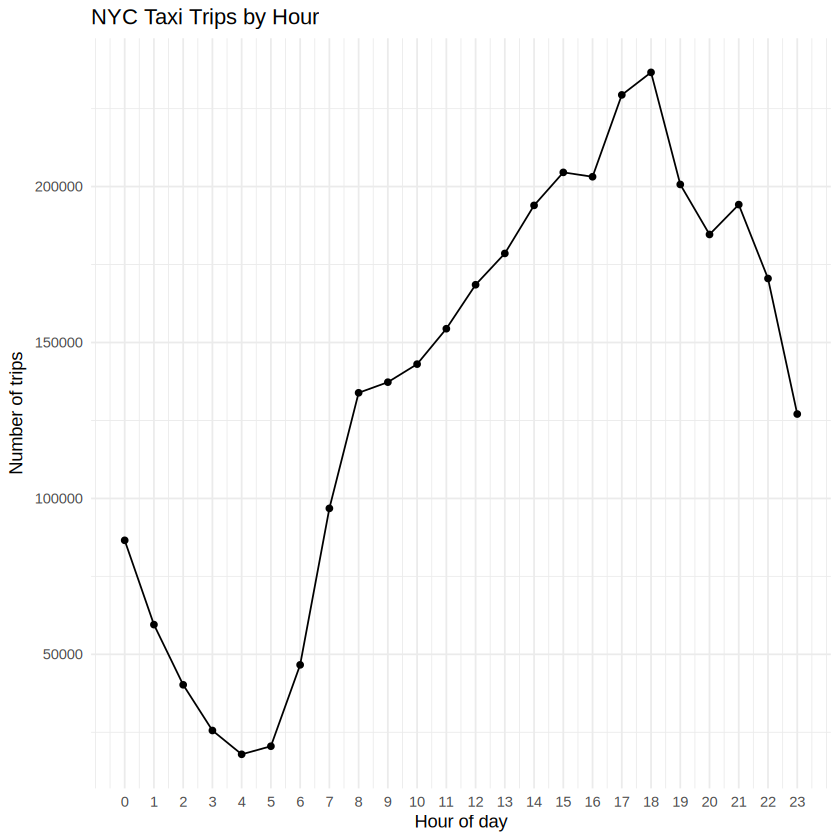

In [10]:
ggplot(hourly_trips, aes(x = hour, y = total_trips)) +
  geom_line() +
  geom_point() +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "NYC Taxi Trips by Hour",
    x = "Hour of day",
    y = "Number of trips"
  ) +
  theme_minimal()

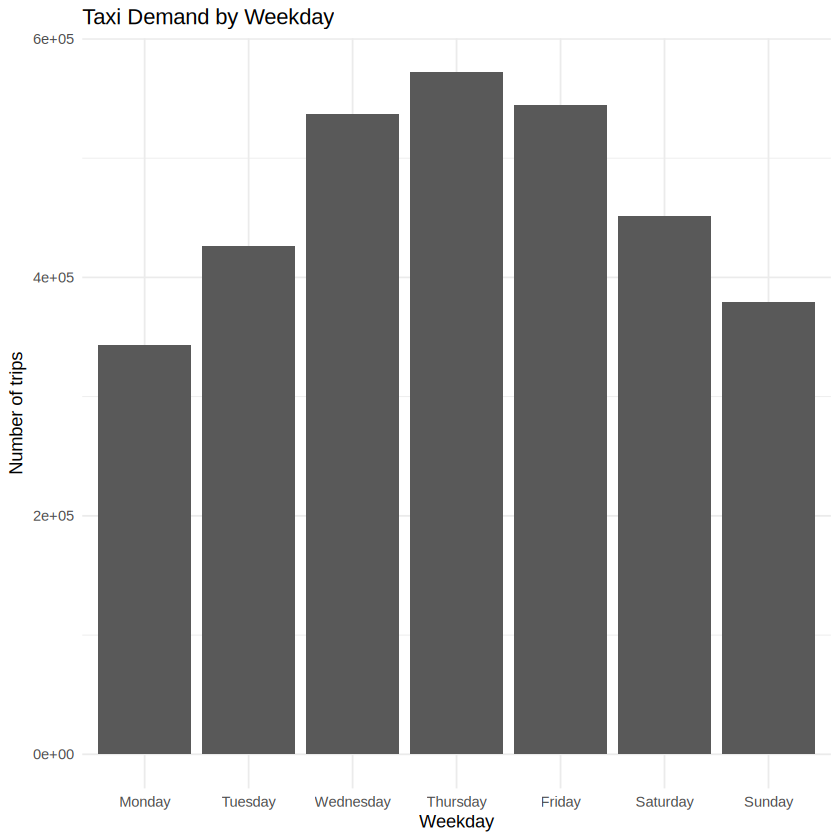

In [11]:
ggplot(weekday_trips, aes(x = weekday, y = total_trips)) +
  geom_col() +
  labs(
    title = "Taxi Demand by Weekday",
    x = "Weekday",
    y = "Number of trips"
  ) +
  theme_minimal()

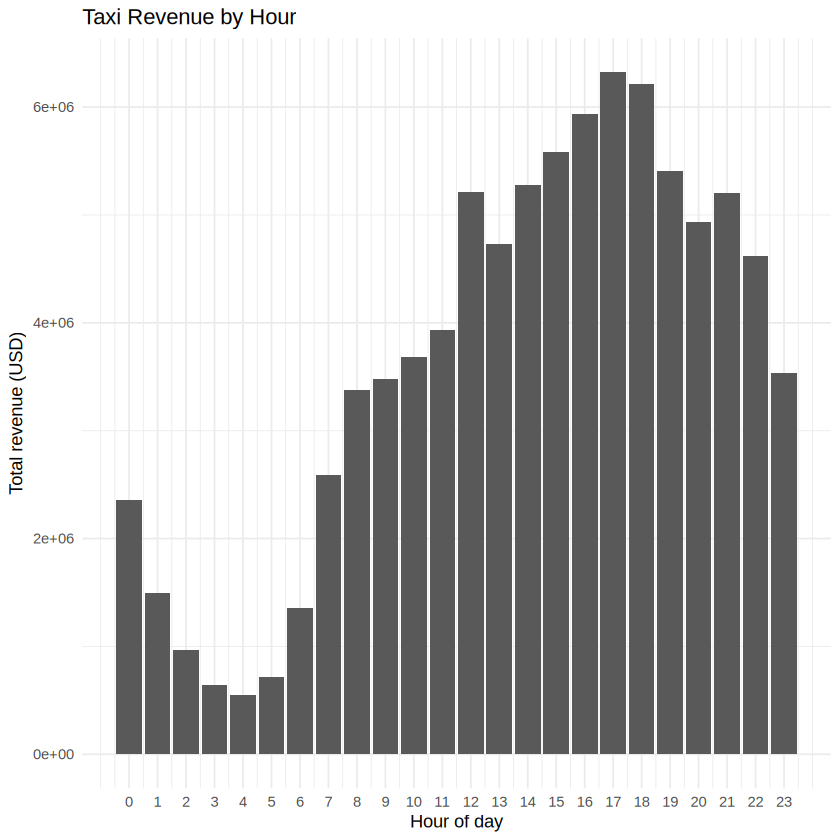

In [12]:
ggplot(hourly_revenue, aes(x = hour, y = total_revenue)) +
  geom_col() +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "Taxi Revenue by Hour",
    x = "Hour of day",
    y = "Total revenue (USD)"
  ) +
  theme_minimal()

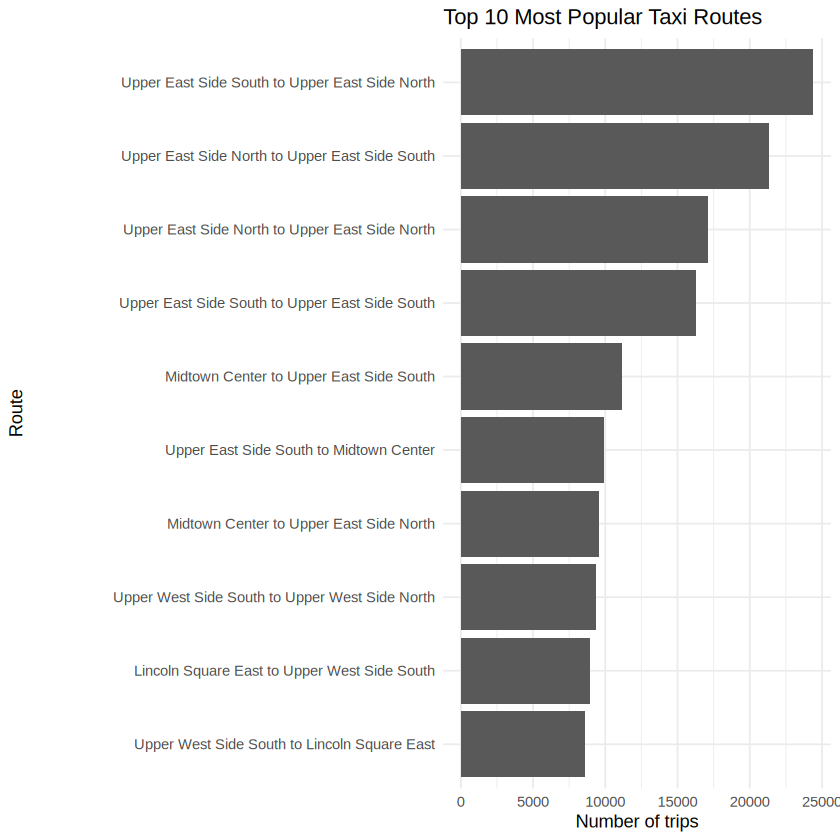

In [13]:
top_routes <- head(popular_routes, 10)

top_routes[, route := paste(
  pickup_zone, "to", dropoff_zone
)]

ggplot(
  top_routes,
  aes(x = reorder(route, total_trips), y = total_trips)
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Top 10 Most Popular Taxi Routes",
    x = "Route",
    y = "Number of trips"
  ) +
  theme_minimal()

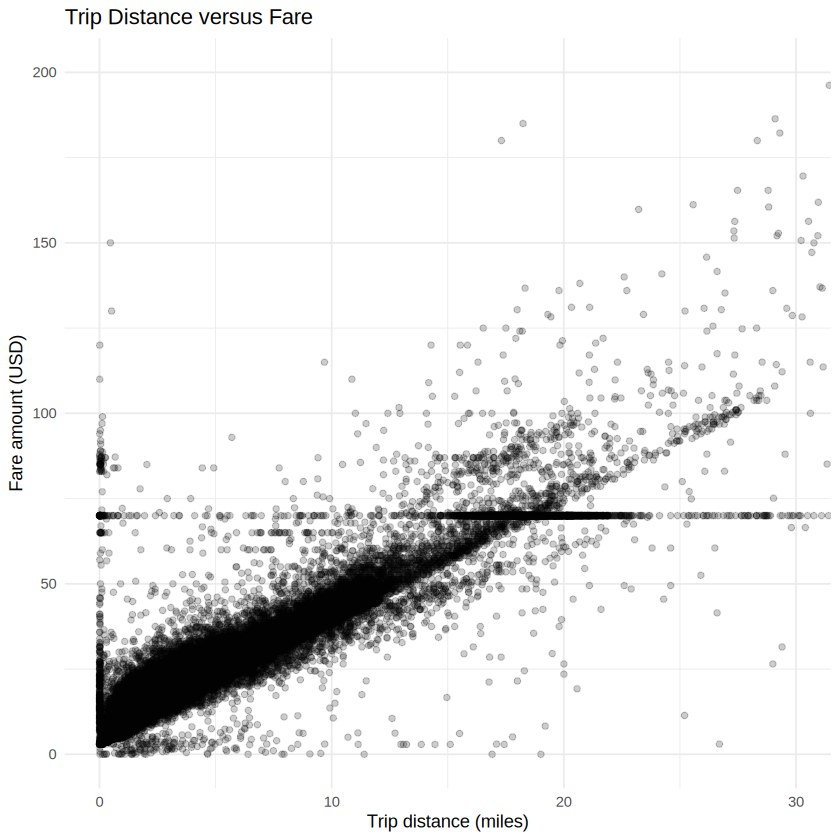

In [14]:
set.seed(42)

sample_n <- min(100000, nrow(trips))
sample_trips <- trips[sample(.N, sample_n)]

ggplot(
  sample_trips,
  aes(x = trip_distance, y = fare_amount)
) +
  geom_point(alpha = 0.2) +
  coord_cartesian(xlim = c(0, 30), ylim = c(0, 200)) +
  labs(
    title = "Trip Distance versus Fare",
    x = "Trip distance (miles)",
    y = "Fare amount (USD)"
  ) +
  theme_minimal()

In [15]:
memory_table <- data.table(
  Object = c(
    "Raw dataset",
    "Cleaned dataset",
    "Benchmark sample"
  ),
  Approx_MB = c(
    as.numeric(object.size(trips_raw)) / 1024^2,
    as.numeric(object.size(trips)) / 1024^2,
    as.numeric(object.size(bench_data)) / 1024^2
  )
)

print(memory_table)

             Object Approx_MB
             <char>     <num>
1:      Raw dataset 450.74134
2:  Cleaned dataset 347.64336
3: Benchmark sample  10.72125


In [16]:
cat("========== FINAL OBSERVATIONS ==========\n")

cat(
  "Peak demand hour:",
  hourly_trips[which.max(total_trips)]$hour,
  "\n"
)

cat(
  "Most popular route:",
  popular_routes[1]$pickup_zone,
  "to",
  popular_routes[1]$dropoff_zone,
  "\n"
)

cat(
  "Highest revenue route:",
  revenue_routes[1]$pickup_zone,
  "to",
  revenue_routes[1]$dropoff_zone,
  "\n"
)

cat("Parallel speedup:", round(speedup, 3), "x\n")

cat("\nBenchmark summary:\n")
print(benchmark_summary)

cat("\nMemory summary:\n")
print(memory_table)

cat("\n========================================\n")

========== FINAL OBSERVATIONS ==========
Peak demand hour: 18 
Most popular route: Upper East Side South to Upper East Side North 
Highest revenue route: LaGuardia Airport to Astoria Park 
Parallel speedup: 0.012 x

Benchmark summary:
   Implementation    Min_ms Median_ms   Mean_ms
           <char>     <num>     <num>     <num>
1:     Vectorized  1.441420  1.623142  3.005793
2:      DataTable  9.722371 11.352210 14.224347
3:         Lapply 15.053821 15.564857 19.072655
4:      Base_Loop 12.999208 15.705258 15.329196

Memory summary:
             Object Approx_MB
             <char>     <num>
1:      Raw dataset 450.74134
2:  Cleaned dataset 347.64336
3: Benchmark sample  10.72125

